<a href="https://colab.research.google.com/github/sugarfreecat/estatistica_descritiva/blob/main/notebooks/01_estatistica_descritiva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![title](https://ik.imagekit.io/vzr6ryejm/colab/jupyter_notebook-ad.drawio.png)

# 📘 Introdução à Estatística Descritiva

### 🎯 O que você vai aprender
- O que é estatística e a diferença entre **descritiva** e **inferencial**
- Termos básicos: **dados, população, amostra e variáveis** (e seus tipos)
- Como **resumir dados** com **média, mediana, moda, amplitude, variância e desvio padrão**
- Como **descrever a forma da distribuição** com **assimetria** e **histograma**
- Como **dividir os dados em partes** com **quartis, percentis e IQR**, e **identificar valores atípicos (outliers)** com o box plot

### 💡 Dica antes de começar
Para executar uma célula de código, clique nela e aperte **Shift + Enter**. Vá sempre **de cima para baixo**. Os dados são **fictícios** (gerados com a biblioteca Faker), então não há nenhuma informação de pessoas reais. Por isso, as conclusões valem **apenas para esta base**: servem para aprender o método, não para tirar conclusões sobre estudantes de verdade.

> ℹ️ Os textos de interpretação foram escritos para a **base padrão** (50 linhas, semente 21). Os números calculados nas células sempre se atualizam; se você gerar outra base, alguns comentários podem precisar de ajuste.

## 📊 O que é estatística?
**Estatística** é a ciência de **coletar, organizar, analisar e interpretar dados** para transformar números soltos em informação útil. Ela ajuda a tomar decisões no dia a dia, nos negócios e na pesquisa.

Existem dois grandes ramos:

| | **Estatística descritiva** | **Estatística inferencial** |
|---|---|---|
| O que faz | **Resume** os dados que temos | Usa uma amostra para **estimar e testar** algo sobre um grupo maior |
| Pergunta típica | "O que aconteceu **nestes** dados?" | "O que provavelmente vale para o **grupo todo**, e com que margem de erro?" |
| Exemplo | "A nota média dos 50 alunos é 6,1" | "A nota média de *todos* os alunos da escola deve ser parecida com 6,1, com margem de erro de ±X" |

👉 Neste notebook trabalhamos somente com a **Análise Descritiva**: tudo o que calcularmos descreve **estes 50 alunos**. Para generalizar para a escola inteira, seria preciso a inferencial (intervalos de confiança, testes de hipótese), além de saber **como a amostra foi escolhida**: uma amostra aleatória permite generalizar; uma amostra de conveniência, não.

## 📈 Termos fundamentais

| Termo | O que é | Na nossa base |
|---|---|---|
| **Dados** | informações coletadas para análise | o conteúdo da tabela |
| **População** | o grupo **inteiro** que queremos estudar | todos os alunos da escola |
| **Amostra** | uma **parte** da população | os 50 alunos da tabela |
| **Variável** | uma característica que **varia** de aluno para aluno | cada coluna |

## 🔡 Tipos de variável
- **Qualitativa** (categoria)
  - **Nominal** (sem ordem natural): `curso`, `turno`, `mes_da_matricula`. A coluna `id_aluno` também é nominal, mas é só um **identificador**: não faz sentido calcular estatísticas com ela.
  - **Ordinal** (categorias com ordem): `nivel_engajamento` (Baixo < Médio < Alto)
- **Quantitativa** (número)
  - **Discreta**: valores que **contamos** (0, 1, 2 faltas...) → `numero_de_faltas`
  - **Contínua**: valores que **medimos** (nota 7,3; renda R$ 3.450,50...) → `nota_final`, `nota_diagnostico`, `horas_estudo_semana`, `horas_sono_noite`, `renda_familiar_mensal`, `aproveitamento_atividades_pct` e `tempo_de_deslocamento_min` (medido em minutos inteiros, mas por natureza contínuo)

💡 **Por que isso importa?** O tipo da variável decide **quais medidas fazem sentido**:
- **Moda** funciona para qualquer tipo.
- **Mediana e quartis** exigem **ordem** (ordinais e quantitativas).
- **Média, variância e desvio padrão** exigem variável **quantitativa**.

## 🔧 Preparação
Esta primeira célula carrega as ferramentas e os dados. Você só precisa executá-la.

### 📚 Importando as Bibliotecas

In [ ]:
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

import numpy as np                 # contas matemáticas (ex.: raiz quadrada)
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (10, 6)    # tamanho padrão dos gráficos

### 🔄 Carregando a base de dados

In [ ]:
drive.mount("/content/drive")      # vai pedir autorização na primeira vez
pasta_colab = Path("/content/drive/MyDrive/Colab Notebooks") # pasta dos notebooks do Colab no Google Drive
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/estatistica/dados") # pasta onde a base de dados fica guardada no Drive
caminho_do_csv = pasta_dados / "alunos.csv"

# Se o arquivo ainda não existir no Drive, pede o upload e grava na pasta indicada
if not caminho_do_csv.exists():
    pasta_dados.mkdir(parents=True, exist_ok=True)   # cria a pasta "dados" se faltar
    print("Base não encontrada. Selecione o arquivo CSV para enviar:")
    enviados = files.upload()                        # abre o seletor de arquivos
    nome_enviado = next(iter(enviados))              # nome do arquivo escolhido
    shutil.move(nome_enviado, caminho_do_csv)        # move o arquivo enviado para a pasta de dados (alunos.csv)
    print(f"Arquivo salvo em: {caminho_do_csv}")

dados = pd.read_csv(caminho_do_csv)
dados.head()

Mounted at /content/drive


,id_aluno,curso,turno,mes_da_matricula,horas_estudo_semana,horas_sono_noite,numero_de_faltas,nota_final,renda_familiar_mensal,tempo_de_deslocamento_min,nota_diagnostico,aproveitamento_atividades_pct,nivel_engajamento
0,ALU-2664-EN,Saúde,Tarde,Jan,14.5,6.9,2,8.3,26709.31,45,7.5,70.5,Alto
1,ALU-1107-KJ,Direito,Tarde,Jan,15.4,8.2,2,8.5,5607.19,86,8.9,84.5,Alto
2,ALU-8645-CG,Engenharia,Noite,Abr,9.3,7.2,7,3.8,3604.23,24,3.2,57.6,Médio
3,ALU-0836-KV,Engenharia,Noite,Ago,6.1,7.1,4,4.3,2684.80,44,2.9,22.7,Baixo
4,ALU-7042-PH,Saúde,Tarde,Jan,20.2,6.4,1,8.8,2993.52,48,4.8,66.5,Alto


## 1️⃣ Conhecendo a nossa base de dados

### Número de Linhas e Colunas

In [ ]:
# Quantas linhas (alunos) e colunas (variáveis) tem a base?
linhas, colunas = dados.shape
print(f"A base tem {linhas} linhas (alunos) e {colunas} colunas (variáveis)")

A base tem 50 linhas (alunos) e 13 colunas (variáveis)


### Checar os tipos de dados de cada variável (coluna) do DataFrame

In [ ]:
dados.dtypes # Tipos de dados das colunas

,0
id_aluno,object
curso,object
turno,object
mes_da_matricula,object
horas_estudo_semana,float64
horas_sono_noite,float64
numero_de_faltas,int64
nota_final,float64
renda_familiar_mensal,float64
tempo_de_deslocamento_min,int64


#### 🔎 O que os tipos mostram
Das 13 colunas, **5** são texto (`object`: `id_aluno`, `curso`, `turno`, `mes_da_matricula`, `nivel_engajamento`), **6** são decimais (`float64`) e **2** são inteiras (`int64`: `numero_de_faltas` e `tempo_de_deslocamento_min`).

⚠️ O tipo do Pandas é **computacional**, não estatístico: `nivel_engajamento` aparece como `object`, mas é **ordinal** (Baixo < Médio < Alto), e `tempo_de_deslocamento_min` é `int64`, mas é uma medida **contínua** arredondada. Cabe a quem analisa decidir o tipo estatístico de cada variável.

## 2️⃣ Média
É a **soma** de todos os valores dividida pela **quantidade** de valores:

$$\bar{x} = \frac{\sum x_i}{n}$$

Mostra o **desempenho geral** do grupo, o "ponto de equilíbrio" dos dados. Seu ponto fraco: ela é **sensível a valores extremos**, pois cada valor, por mais distante que seja, entra na conta. Para enxergar a conta, vamos usar **só 5 alunos** primeiro.

### Média Manual selecionando 5 alunos

In [ ]:
# Pegamos as notas dos 5 primeiros alunos
cinco_notas = dados["nota_final"].head(5)
print("Notas:", cinco_notas.tolist())

# Passo 1: somar todas as notas
soma = cinco_notas.sum()

# Passo 2: contar quantas notas existem
quantidade = len(cinco_notas)

# Passo 3: dividir a soma pela quantidade
media_manual = soma / quantidade

print(f"Média = {soma:.1f} / {quantidade} = {media_manual:.2f}")
print(f"Conferindo com .mean(): {cinco_notas.mean():.2f}")

Notas: [8.3, 8.5, 3.8, 4.3, 8.8]
Média = 33.7 / 5 = 6.74
Conferindo com .mean(): 6.74


### Média - Notas de todos os alunos

In [ ]:
# Agora com TODOS os alunos, é só uma linha:
media_de_todos = dados["nota_final"].mean()     # mean() calcula a média
print(f"Nota média dos {len(dados)} alunos: {media_de_todos:.2f}")

Nota média dos 50 alunos: 6.09


#### 🔎 Interpretação
A nota média da turma é **6,09**. Repare que a média dos 5 primeiros alunos (6,74) difere em 0,65 ponto da média dos 50: com poucos alunos, o resultado **oscila bastante** conforme quem entra na amostra. Quanto maior a amostra, mais estável a média.

A média informa o **centro**, mas **não diz o quanto os alunos se afastam dele**: duas turmas com média 6,09 podem ter notas todas próximas de 6 ou metade em 2 e metade em 10. Para isso servem as medidas de dispersão (seções 5 a 8).

## 3️⃣ Mediana
É o **valor do meio** quando os dados estão **em ordem**. Metade dos valores fica abaixo dela e metade acima.
- Quantidade **ímpar** → o valor central.
- Quantidade **par** → a média dos dois valores centrais.

### Mediana - Quantidade Ímpar (5 alunos)
Com 5 notas, a mediana é o **3º valor** da lista ordenada. O código ordena as notas para você ver o valor central e usa `.median()` para conferir.

In [ ]:
notas_ordenadas = cinco_notas.sort_values().to_list()  # sort_values() ordena as notas em ordem crescente
print("Notas ordenadas:", notas_ordenadas)
print("Mediana: ", cinco_notas.median())   # confere com a função median()

Notas ordenadas: [3.8, 4.3, 8.3, 8.5, 8.8]
Mediana:  8.3


### Mediana - Quantidade Par (6 alunos)
Com 6 notas não existe um único valor central: a mediana é a **média dos dois do meio** (3º e 4º valores da lista ordenada). Aqui o cálculo é feito manualmente e conferido com `.median()`.

In [ ]:
seis_notas = dados["nota_final"].head(6)
notas_ordenadas = seis_notas.sort_values().to_list()  # sort_values() ordena as notas em ordem crescente
print("Notas ordenadas:", notas_ordenadas)

# Mediana manual: média dos dois valores centrais
notas_centrais = notas_ordenadas[2:4]
mediana_manual = sum(notas_centrais) / len(notas_centrais)
print("Mediana = ", mediana_manual)

# Mediana com a função do Pandas, para conferir
print("Mediana: ", seis_notas.median())

Notas ordenadas: [3.8, 4.3, 6.7, 8.3, 8.5, 8.8]
Mediana =  7.5
Mediana:  7.5


### Mediana - Notas de todos os alunos

In [ ]:
# Agora com TODOS os alunos, é só uma linha:
mediana_de_todos = dados["nota_final"].median()     # median() calcula a mediana
print(f"Nota mediana dos {len(dados)} alunos: {mediana_de_todos:.2f}")

Nota mediana dos 50 alunos: 6.25


#### 🔎 Interpretação e comparação com a média
- **Nos 5 alunos:** média **6,74** e mediana **8,3**. A mediana é bem maior porque as duas notas baixas (3,8 e 4,3) **puxam a média para baixo**, enquanto a mediana só olha a posição central. Esse é o exemplo clássico de que a **mediana resiste a valores extremos** e a média não.
- **Nos 50 alunos:** média **6,09** e mediana **6,25**, muito próximas. Quando média ≈ mediana, é sinal de distribuição simétrica (confirmado pela assimetria, logo adiante).

**Regra de bolso:** média muito diferente da mediana indica assimetria ou valores extremos. Nesse caso, a mediana costuma ser o melhor resumo do "aluno típico". Também é por isso que **renda** costuma ser descrita pela mediana (poucas rendas muito altas inflam a média).

### Gráfico Histograma - Média e Mediana de todos os alunos

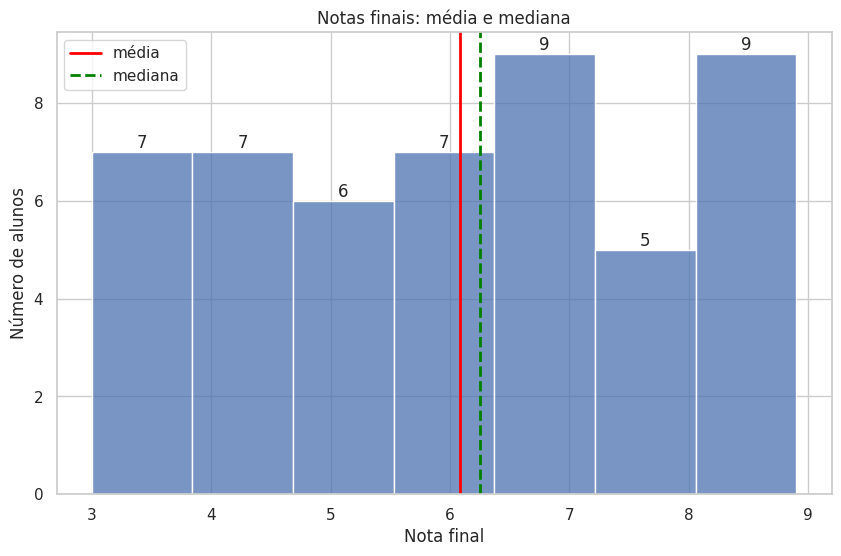

In [ ]:
ax = sns.histplot(data=dados, x="nota_final", bins=7)   # histograma das notas (7 faixas)

for container in ax.containers:
    ax.bar_label(container)                     # escreve a contagem acima de cada barra

plt.axvline(dados["nota_final"].mean(), color="red", linewidth=2, label="média")
plt.axvline(dados["nota_final"].median(), color="green", linestyle="--", linewidth=2, label="mediana")
plt.title("Notas finais: média e mediana")
plt.xlabel("Nota final")
plt.ylabel("Número de alunos")
plt.legend()
plt.show()

#### 🔎 Como ler o histograma
Cada barra mostra **quantos alunos** têm nota dentro de uma faixa; os números acima das barras são essas contagens. A linha **vermelha** marca a média (6,09) e a **verde tracejada** a mediana (6,25): estão quase **sobrepostas**, o que reforça a ideia de distribuição aproximadamente simétrica.

⚠️ O formato do histograma depende do **número de faixas** (`bins=7`). Com apenas 50 alunos, pequenas mudanças em `bins` podem alterar bastante a aparência (por exemplo, fazer surgir ou desaparecer um "pico"). Vale testar outros valores antes de concluir algo sobre o formato.

### O quanto a distribuição dos dados é simétrica em relação ao seu centro?

* **Skew ≈ 0:** distribuição simétrica. Os dados se espalham de forma parecida dos dois lados da média, e média e mediana ficam próximas.
* **Skew negativo:** assimetria à esquerda. A cauda do gráfico se estica para os valores baixos, e a média fica abaixo da mediana.
* **Skew positivo:** assimetria à direita. A cauda se estica para os valores altos, e a média fica acima da mediana.

**Regra prática:** valores entre -0,5 e 0,5 indicam distribuição aproximadamente simétrica. Entre 0,5 e 1 (em módulo), assimetria moderada. Acima de 1, forte.

> ℹ️ O `.skew()` do Pandas calcula a assimetria **amostral** (Fisher-Pearson ajustada). Com poucos dados ela é instável: para n = 50, o erro-padrão da assimetria é de cerca de **0,34**, então valores de até ±0,7 não se distinguem de zero com segurança.

In [ ]:
dados["nota_final"].skew()  # Calcula a assimetria

np.float64(-0.03749106115678723)

O coeficiente de assimetria foi de **-0,04**, praticamente zero. Isso é coerente com o que vimos antes: média (6,09) e mediana (6,25) estão muito próximas (diferença de apenas 0,16 ponto, cerca de 0,09 desvio padrão).

**Conclusão:** a distribuição das notas é **aproximadamente simétrica**, sem cauda longa para nenhum dos lados. Isso quer dizer que, neste caso, **média e mediana descrevem o centro da turma de forma equivalente**. (A média ligeiramente abaixo da mediana é só um indício muito fraco de uma cauda para as notas baixas, bem dentro da margem de erro.)

⚠️ Assimetria descreve **a forma** da distribuição, não se as notas são boas ou ruins.

## 4️⃣ Moda
É o valor que **mais se repete**. Funciona muito bem para **categorias** e **contagens**.

- Pode haver **mais de uma moda** (distribuição bimodal) ou **nenhuma** moda clara. O `.mode()` devolve **todas** as modas; o `[0]` do código pega só a primeira.
- Para variáveis **contínuas** (como `nota_final`), quase nenhum valor se repete, então a moda perde utilidade. Nesses casos usa-se o **histograma** para ver onde os dados se concentram.

In [ ]:
# Moda de uma variável QUALITATIVA: qual turno tem mais alunos?
print("Turno mais frequente:", dados["turno"].mode()[0])      # mode() devolve uma lista; [0] pega a primeira

# Quantidade de alunos por turno
print("\nQuantidade de alunos por turno:")
print(dados["turno"].value_counts())

# Moda de uma variável DISCRETA: quantas faltas aparecem mais vezes?
print("\nNúmero de faltas mais comum:", dados["numero_de_faltas"].mode()[0])

# Quantidade de faltas
print("\nContagem de faltas:")
print(dados["numero_de_faltas"].value_counts())

Turno mais frequente: Tarde

Quantidade de alunos por turno:
turno
Tarde    19
Noite    18
Manhã    13
Name: count, dtype: int64

Número de faltas mais comum: 3

Contagem de faltas:
numero_de_faltas
3     12
5      8
2      7
4      7
8      4
6      3
1      3
7      2
0      2
11     1
9      1
Name: count, dtype: int64


### Moda da `nota_final` (variável contínua)
O `.mode()` devolve **todas** as modas, em ordem crescente, e `.tolist()` transforma o resultado em uma lista. Em variáveis contínuas é comum haver **empate** entre vários valores (cada um aparecendo poucas vezes), então a lista pode ter mais de um elemento. Por isso a moda é pouco informativa aqui, e o histograma descreve melhor onde as notas se concentram.

In [ ]:
# Moda de uma variável CONTÍNUA: mode() devolve todas as modas (em ordem crescente)
modas_nota_final = dados["nota_final"].mode().tolist()
repeticoes = dados["nota_final"].value_counts().max()   # quantas vezes a(s) moda(s) aparece(m)

print("Moda(s) da nota_final:", modas_nota_final)
print(f"Cada moda aparece {repeticoes} vez(es) entre os {len(dados)} alunos")

Moda(s) da nota_final: [3.8, 4.3, 5.3, 5.8, 6.3, 6.7, 8.0, 8.8]
Cada moda aparece 2 vez(es) entre os 50 alunos


#### 🔎 Interpretação
A `nota_final` tem **8 modas empatadas** (3,8; 4,3; 5,3; 5,8; 6,3; 6,7; 8,0 e 8,8), e cada uma aparece **apenas 2 vezes** entre os 50 alunos (4% da turma). Como não há um valor que se destaque, a moda **não resume nada** aqui: ela é só um efeito de coincidências em uma variável contínua.

Isso confirma o que foi dito: para notas, o **histograma**, a média e a mediana descrevem a turma muito melhor. A moda é útil sobretudo para categorias (como o turno) e contagens (como as faltas).

### Gráfico de Colunas - Quantos alunos tem cada número de faltas?

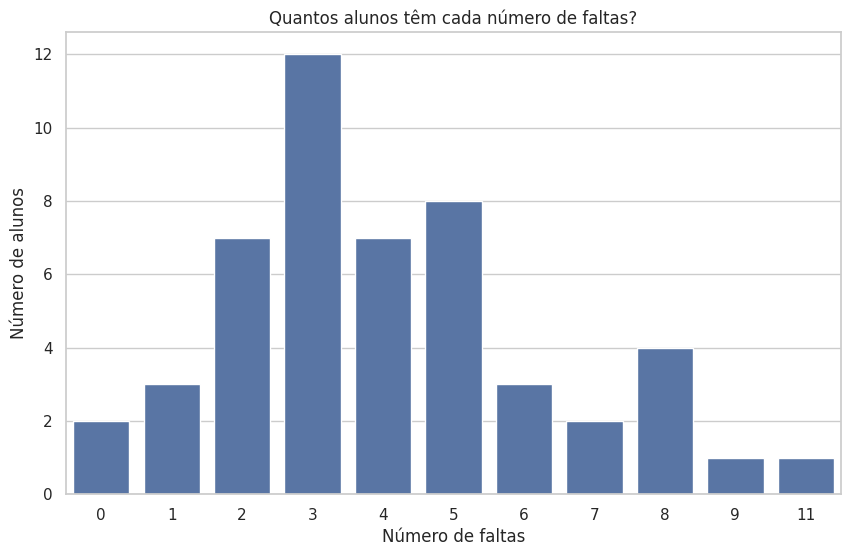

In [ ]:
# Gráfico de colunas: a moda é a coluna mais alta
sns.countplot(data=dados, x="numero_de_faltas")     # countplot conta quantas vezes cada valor aparece
plt.title("Quantos alunos têm cada número de faltas?")
plt.xlabel("Número de faltas")
plt.ylabel("Número de alunos")
plt.show()

#### 🔎 Interpretação
**Turno** (variável qualitativa):

| Turno | Alunos | % |
|---|---|---|
| Tarde | 19 | 38% |
| Noite | 18 | 36% |
| Manhã | 13 | 26% |

A moda é **Tarde**, mas com apenas **1 aluno a mais** que a Noite: na prática, os dois turnos estão **empatados**, e a diferença poderia mudar com outra amostra. O turno da Manhã é claramente o menos frequente.

**Número de faltas** (variável discreta): a moda é **3 faltas** (12 alunos, 24% da turma). A maior parte da turma se concentra entre 2 e 5 faltas (7 + 12 + 7 + 8 = **34 alunos, 68%**). Há uma **cauda à direita**: 6 alunos (12%) têm 8 faltas ou mais, chegando a 11.

Fazendo a conta a partir da tabela de contagens (esses valores não aparecem no output do notebook), a média de faltas é cerca de **4,1** e a mediana **4**, ambas acima da moda (3). Moda < mediana ≲ média é o padrão de uma **assimetria à direita**: poucos alunos com muitas faltas puxam a média para cima. Esse é um exemplo de variável em que a moda sozinha **subestima** o comportamento da turma.

⚠️ No gráfico, o eixo mostra apenas os valores que existem: **não aparece "10"** porque ninguém tem 10 faltas. Isso "encurta" visualmente o espaço entre 9 e 11 e pode dar a impressão de uma sequência contínua.

## 5️⃣ Amplitude
Mostra **quão espalhados** estão os dados: a diferença entre o **maior** e o **menor** valor.

$$A = x_{máx} - x_{mín}$$

É a medida de dispersão mais simples, mas também a mais frágil: usa **apenas os dois extremos** e ignora como os demais valores estão distribuídos.

In [ ]:
maior_nota = dados["nota_final"].max()    # max() devolve o maior valor
menor_nota = dados["nota_final"].min()    # min() devolve o menor valor
amplitude = maior_nota - menor_nota

print(f"Amplitude = {maior_nota} - {menor_nota} = {amplitude:.1f} pontos")

Amplitude = 8.9 - 3.0 = 5.9 pontos


A amplitude das notas foi de **5,9 pontos** (de 3,0 a 8,9): o pior e o melhor desempenho da turma estão separados por quase 6 pontos numa escala de 0 a 10.

**Como interpretar:**
- Como a amplitude só olha os extremos, um único aluno atípico poderia "inflá-la". Aqui isso **não** parece ocorrer: o box plot (seção 8) não aponta nenhum outlier, então os extremos são representativos.
- Nenhum aluno ficou abaixo de 3,0 nem chegou a 9,0: a turma não tem notas muito baixas nem excelentes.
- Comparada ao desvio padrão (1,78), a amplitude equivale a cerca de **3,3 desvios padrão**. Em 50 observações de uma distribuição normal, costuma-se ver algo em torno de 4 a 5 desvios, então a turma parece ter **caudas mais curtas** que o normal.

👉 Para saber como a **maioria** está distribuída, precisamos de medidas que usem todos os valores: variância, desvio padrão e IQR.

## 6️⃣ Variância
A **variância** mede **o quanto os valores se afastam da média**. Ela é o passo que vem **antes** do desvio padrão.

**Passo a passo:**
1. Calcule a **média**.
2. **Subtraia a média** de cada valor.
3. **Eleve cada diferença ao quadrado** (assim, diferenças positivas e negativas não se cancelam e afastamentos grandes pesam mais).
4. **Some** todos os quadrados.
5. **Divida** pela quantidade de dados.

$$\sigma^2 = \frac{\sum (x_i - \mu)^2}{N} \quad \text{(população)} \qquad\qquad s^2 = \frac{\sum (x_i - \bar{x})^2}{n-1} \quad \text{(amostra)}$$

> ⚠️ Use **$N$** quando os dados são a **população inteira** e **$n-1$** quando são uma **amostra** (o caso mais comum). O Pandas usa **$n-1$** por padrão (`ddof=1`); já o NumPy (`np.var`, `np.std`) usa **$N$** por padrão (`ddof=0`). Misturar as duas bibliotecas sem perceber é uma fonte clássica de resultados "diferentes".

> 💡 O $n-1$ (correção de Bessel) compensa o fato de a amostra, em média, subestimar a dispersão da população. O efeito é grande com poucos dados (5 alunos: dividir por 4 em vez de 5 aumenta o resultado em 25%) e pequeno com muitos (50 alunos: apenas 2%).

> 💡 Como as diferenças são elevadas ao quadrado, a variância fica em **unidades ao quadrado** (notas viram "pontos²"), o que é difícil de interpretar. É por isso que existe o desvio padrão (próxima seção).

De novo, começamos pequeno, com os 5 alunos:

### Cálculo manual da Variância

In [ ]:
media = cinco_notas.mean()                                           # passo 1: média

tabela_da_conta = pd.DataFrame({"nota": cinco_notas})
tabela_da_conta["nota - média"] = cinco_notas - media                # passo 2: diferença para a média
tabela_da_conta["(nota - média)²"] = (cinco_notas - media) ** 2      # passo 3: elevar ao quadrado
display(tabela_da_conta.round(2))

soma_dos_quadrados = tabela_da_conta["(nota - média)²"].sum()        # passo 4: somar
print(f"Soma dos quadrados = {soma_dos_quadrados:.2f}")

variancia_populacional = soma_dos_quadrados / 5                      # passo 5 (÷ N)
variancia_amostral = soma_dos_quadrados / (5 - 1)                    # passo 5 (÷ n−1)
print(f"Variância Populacional (÷ N) = {variancia_populacional:.2f} pontos²")
print(f"Variância Amostral (÷ n-1) = {variancia_amostral:.2f} pontos²")

,nota,nota - média,(nota - média)²
0,8.3,1.56,2.43
1,8.5,1.76,3.10
2,3.8,-2.94,8.64
3,4.3,-2.44,5.95
4,8.8,2.06,4.24


Soma dos quadrados = 24.37
Variância Populacional (÷ N) = 4.87 pontos²
Variância Amostral (÷ n-1) = 6.09 pontos²


### Cálculo da Variância via função

In [ ]:
print(f"Variância Populacional (÷ N) = {cinco_notas.var(ddof=0):.2f} pontos²")
print(f"Variância Amostral (÷ n-1) = {cinco_notas.var():.2f} pontos²")

Variância Populacional (÷ N) = 4.87 pontos²
Variância Amostral (÷ n-1) = 6.09 pontos²


A variância **populacional** foi de 4,87 e a **amostral** de 6,09 (para os 5 alunos). Como a amostral divide por n-1, o resultado é maior (exatamente 25% maior, pois 5/4 = 1,25). Ela é a mais indicada quando os alunos analisados representam apenas uma **amostra** de um grupo maior; se a turma inteira fosse a população de interesse, usaríamos a populacional.

Observe também que a variância dos 5 alunos (6,09) é **bem maior** que a dos 50 (3,16, a seguir): esses 5 alunos têm duas notas baixas (3,8 e 4,3) e três altas (8,3 a 8,8), nenhuma no meio, o que exagera a dispersão. Isso ilustra como **amostras muito pequenas** podem dar uma imagem distorcida do grupo.

> 🔎 Coincidência numérica: o valor 6,09 aparece duas vezes neste notebook, como variância amostral dos 5 alunos e como **média** dos 50 alunos. São grandezas diferentes (pontos² vs. pontos), sem relação entre si.

**👉 A variância está em "pontos ao quadrado", então é difícil interpretá-la diretamente. Para ter uma medida na mesma unidade das notas, calculamos a seguir o desvio padrão.**

### Variância - Notas de todos os alunos

In [ ]:
# Com todos os alunos, o Pandas faz tudo de uma vez
variancia = dados["nota_final"].var()
print(f"Variância das notas dos {len(dados)} alunos: {variancia:.2f} pontos²")

Variância das notas dos 50 alunos: 3.16 pontos²


A variância das notas dos 50 alunos foi de **3,16 pontos²** (usando n-1; com n teria sido cerca de 3,10, uma diferença pequena porque a amostra é razoável). Isso equivale a um **desvio padrão de cerca de 1,78 ponto**, que é bem mais fácil de interpretar (próxima seção).

## 7️⃣ Desvio padrão
O **desvio padrão** é a **raiz quadrada da variância**. Com isso, o valor **volta à unidade original** (pontos) e fica fácil de interpretar: indica **o afastamento típico** dos valores em relação à média. Quanto **maior**, mais **espalhados** estão os dados.

$$s = \sqrt{s^2}$$

> 💡 Rigorosamente, o desvio padrão não é a "média dos afastamentos", e sim a **raiz da média dos quadrados** dos afastamentos. Por elevar ao quadrado, ele dá **mais peso a afastamentos grandes**. Na prática, a leitura "afastamento típico" é uma boa aproximação.

**Coeficiente de variação (CV)** = desvio padrão ÷ média. Expressa a dispersão **em % da média** e permite comparar variáveis de unidades diferentes (notas × renda × horas de sono). Como regra prática (que varia por área), CV abaixo de ~15% indica dispersão baixa, entre ~15% e 30% moderada e acima disso alta. Use com cautela em escalas sem zero absoluto, como notas de 0 a 10.

### Cálculo do Desvio Padrão (5 alunos): raiz da variância

In [ ]:
# Usamos a variância que acabamos de calcular e tiramos a raiz quadrada (np.sqrt)
desvio_populacional = np.sqrt(variancia_populacional)
desvio_amostral = np.sqrt(variancia_amostral)

print(f"Desvio padrão Populacional (÷ N)   = raiz de {variancia_populacional:.2f} = {desvio_populacional:.2f}  | Pandas: {cinco_notas.std(ddof=0):.2f}")
print(f"Desvio padrão Amostral (÷ n-1) = raiz de {variancia_amostral:.2f} = {desvio_amostral:.2f}  | Pandas: {cinco_notas.std():.2f}")

Desvio padrão Populacional (÷ N)   = raiz de 4.87 = 2.21  | Pandas: 2.21
Desvio padrão Amostral (÷ n-1) = raiz de 6.09 = 2.47  | Pandas: 2.47


### Desvio Padrão - Notas de todos os alunos

In [ ]:
# Com todos os alunos, o Pandas calcula direto (usa n-1 por padrão)
desvio_padrao = dados["nota_final"].std()
print(f"Desvio padrão das notas dos {len(dados)} alunos: {desvio_padrao:.2f}")

print(f"Interpretação: as notas se afastam, em média, cerca de {desvio_padrao:.1f} ponto da média ({dados['nota_final'].mean():.2f}).")

Desvio padrão das notas dos 50 alunos: 1.78
Interpretação: as notas se afastam, em média, cerca de 1.8 ponto da média (6.09).


#### 🔎 Interpretação
O desvio padrão das notas é **1,78 ponto**: os alunos se afastam da média (6,09) tipicamente cerca de 1,8 ponto, para mais ou para menos. O **coeficiente de variação é de aproximadamente 29%** (1,78 ÷ 6,09), uma dispersão **moderada**, no limite superior da faixa moderada pela regra prática da seção anterior.

Como referência, o intervalo **média ± 1 desvio padrão** vai de cerca de **4,3 a 7,9**. Em uma distribuição aproximadamente normal, cerca de 68% dos alunos cairiam nessa faixa.

Comparando com os 5 alunos (desvio padrão de 2,47 usando n-1), vemos de novo que **amostras pequenas** podem exagerar ou minimizar a dispersão.

⚠️ Lembre: `.std()` do Pandas usa n-1; `np.std()` usa N por padrão. Ao comparar resultados de bibliotecas diferentes, confira o `ddof`.

## 8️⃣ Quartis, percentis e IQR
São medidas de **posição**: dividem os dados **em ordem** em partes iguais.

| Medida | Divide em | Significado |
|---|---|---|
| **Quartis** (Q1, Q2, Q3) | 4 partes | Q1 = 25% dos valores ficam abaixo · Q2 = **mediana** (50%) · Q3 = 75% |
| **Percentis** (P1 a P99) | 100 partes | P90 = 90% dos valores ficam abaixo dele |
| **IQR** | | $IQR = Q_3 - Q_1$: a "largura" dos 50% do meio |

💡 O quartil é só um **tipo de percentil** (Q1 = P25, Q2 = P50, Q3 = P75). Por isso o Pandas usa **a mesma função** para os dois: `.quantile()`, passando um número de 0 a 1. Por padrão ele **interpola** entre os dois valores vizinhos, então o resultado pode ser um número que **não existe** na base (por exemplo, 4,375).

🔎 **Regra de Tukey para outliers:** um valor é considerado atípico se ficar **abaixo de $Q_1 - 1{,}5 \times IQR$** ou **acima de $Q_3 + 1{,}5 \times IQR$**. É exatamente essa regra que o box plot usa para desenhar os pontos isolados fora dos "bigodes". Diferente da média e do desvio padrão, quartis e IQR **não são afetados por valores extremos**.

### Quartis

In [ ]:
notas = dados["nota_final"]

# Quartis: 0.25 = Q1, 0.50 = Q2 (mediana), 0.75 = Q3
q1 = notas.quantile(0.25)
q2 = notas.quantile(0.50)
q3 = notas.quantile(0.75)
iqr = q3 - q1  # IQR = Q3 - Q1

# Regra de Tukey para Limites de Outliers
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Filtrando os outliers (notas abaixo do limite inferior ou acima do superior)
outliers = notas[(notas < limite_inferior) | (notas > limite_superior)]

# Exibindo os resultados formatados
print(f"Q1 = {q1:.2f}  (25% dos alunos tiraram até essa nota)")
print(f"Q2 = {q2:.2f}  (a mediana: o meio)")
print(f"Q3 = {q3:.2f}  (75% dos alunos tiraram até essa nota)")
print(f"IQR = {q3:.2f} - {q1:.2f} = {iqr:.2f}  (os 50% do meio estão nesse intervalo)")
print("-" * 50)
print(f"Limite Inferior (Tukey): {limite_inferior:.2f}")
print(f"Limite Superior (Tukey): {limite_superior:.2f}")
print(f"Total de outliers encontrados: {len(outliers)}")

if not outliers.empty:
    print("Valores dos outliers:")
    print(outliers)
else:
    print("Nenhum outlier encontrado nesta série.")

Q1 = 4.38  (25% dos alunos tiraram até essa nota)
Q2 = 6.25  (a mediana: o meio)
Q3 = 7.65  (75% dos alunos tiraram até essa nota)
IQR = 7.65 - 4.38 = 3.28  (os 50% do meio estão nesse intervalo)
--------------------------------------------------
Limite Inferior (Tukey): -0.54
Limite Superior (Tukey): 12.56
Total de outliers encontrados: 0
Nenhum outlier encontrado nesta série.


#### 🔎 Interpretação
- **25%** dos alunos tiraram até **4,38**; metade tirou até **6,25**; e **75%** tiraram até **7,65** (ou seja, 25% da turma ficou com nota **acima de 7,65**).
- O **IQR é de 3,28**: os 50% centrais da turma estão numa faixa de cerca de 3,3 pontos (de 4,4 a 7,7).
- Distâncias entre os quartis: Q1 → Q2 = 1,88 e Q2 → Q3 = 1,40. As notas entre o primeiro quartil e a mediana estão **mais espalhadas** que as da mediana ao terceiro quartil, indicando uma leve assimetria à esquerda dentro da caixa (o coeficiente de Bowley, (Q3 + Q1 − 2·Q2) ÷ IQR, dá cerca de -0,15, fraco e consistente com o skew de -0,04).
- **Outliers (regra de Tukey):** os limites são Q1 − 1,5·IQR ≈ -0,54 e Q3 + 1,5·IQR ≈ 12,56. Como as notas vão de 0 a 10, **nenhuma nota poderia ser classificada como atípica** nesta escala.

### Percentis

In [ ]:
# Percentis: é a mesma função, só muda o número
p10 = notas.quantile(0.10)
p90 = notas.quantile(0.90)
print(f"P10 = {p10:.2f}  -> 10% dos alunos tiraram até essa nota")
print(f"P90 = {p90:.2f}  -> 90% dos alunos tiraram até essa nota (só 10% passaram disso)")

# Dá para pedir vários de uma vez, passando uma lista
notas.quantile([0.10, 0.25, 0.50, 0.75, 0.90])

P10 = 3.79  -> 10% dos alunos tiraram até essa nota
P90 = 8.51  -> 90% dos alunos tiraram até essa nota (só 10% passaram disso)


,nota_final
0.10,3.790
0.25,4.375
0.50,6.250
0.75,7.650
0.90,8.510


#### 🔎 Interpretação
- **P10 = 3,79:** 10% dos alunos tiraram até 3,8 (os 10% mais baixos ocupam um trecho de cerca de 0,8 ponto, de 3,0 a 3,8).
- **P90 = 8,51:** só 10% da turma passou de 8,5, e esse grupo está **muito compactado**: do P90 ao máximo (8,9) são apenas 0,4 ponto.
- **80% dos alunos** (entre P10 e P90) ficam entre **3,8 e 8,5**.

O topo da turma é, portanto, **mais concentrado** que a base: as notas altas se amontoam perto de 8,5 a 8,9, enquanto as baixas se espalham mais. Percentis são úteis para definir **faixas de corte** (por exemplo, "os 25% com menor nota precisam de reforço" corresponde a quem está abaixo de Q1).

### Gráfico Box Plot - Representação dos Quartis

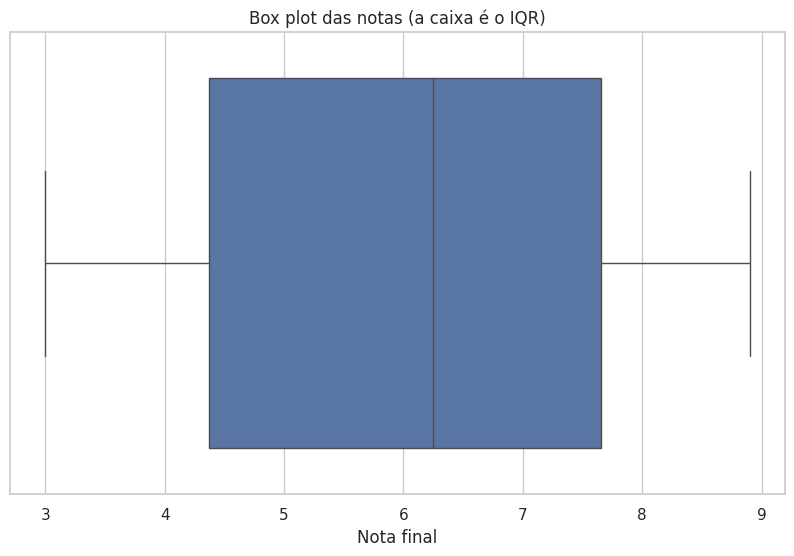

In [ ]:
# O box plot desenha os quartis: a caixa vai de Q1 a Q3 e a linha do meio é a mediana
sns.boxplot(x=dados["nota_final"])
plt.title("Box plot das notas (a caixa é o IQR)")
plt.xlabel("Nota final")
plt.show()

O box plot mostra que as notas variam de **3,0 a 8,9**, com **mediana de 6,25**. Os 50% centrais dos alunos (a caixa) têm notas entre cerca de **4,4 e 7,7**, um IQR de aproximadamente **3,3 pontos**.

**Leitura detalhada:**
- **Simetria:** a mediana fica um pouco acima do centro da caixa (de Q1 à mediana são 1,9 ponto; da mediana a Q3, 1,4 ponto) e os bigodes têm tamanhos parecidos (cerca de 1,4 abaixo e 1,25 acima da caixa). É uma distribuição **aproximadamente simétrica**, com leve alongamento do lado das notas mais baixas, coerente com o skew de -0,04.
- **Outliers:** não há nenhum. Os limites de Tukey seriam -0,54 e 12,56, bem fora da escala de 0 a 10, então **nenhuma nota poderia ser considerada atípica**. Isso valida a média e o desvio padrão como resumos confiáveis desta turma.
- **Dispersão:** o IQR (3,3) é 1,8 vez o desvio padrão (1,78); em uma distribuição normal essa razão seria de cerca de 1,35. Uma razão maior sugere dados mais "espalhados de forma uniforme" e com caudas curtas, o que combina com a amplitude relativamente curta vista antes. A curtose de cerca de -1,21 (seção 5) confirma essa pista.

👉 Um box plot de **uma única variável** mostra a forma geral. O uso mais poderoso é **comparar grupos** (por exemplo, notas por curso ou por turno).

## 🧾 Resumo da análise de `nota_final`

| Medida | Valor | Leitura |
|---|---|---|
| Média | 6,09 | centro da turma |
| Mediana | 6,25 | praticamente igual à média → distribuição simétrica |
| Mínimo / Máximo | 3,0 / 8,9 | ninguém abaixo de 3 nem acima de 9 |
| Amplitude | 5,9 | depende só dos extremos |
| Variância | 3,16 pontos² | difícil de interpretar diretamente |
| Desvio padrão | 1,78 | afastamento típico da média |
| Coeficiente de variação | ≈ 29% | dispersão moderada |
| Assimetria (skew) | -0,04 | simétrica |
| Curtose (excesso) | -1,21 | mais achatada que a normal, caudas leves |
| Q1 / Q3 | 4,38 / 7,65 | 50% centrais da turma |
| IQR | 3,28 | largura da faixa central |
| Outliers | nenhum | média e desvio padrão são resumos confiáveis |

**Conclusão geral:** a turma tem desempenho **mediano, em torno de 6**, com distribuição **simétrica**, dispersão **moderada** (os alunos se afastam cerca de 1,8 ponto da média) e **sem valores atípicos**. Como não há assimetria nem outliers, média e mediana são equivalentes aqui, e o par **média ± desvio padrão** resume bem a turma.

### ⚠️ Limitações
- **n = 50** e dados **fictícios**: nada aqui se generaliza para alunos reais.
- Estatística **descritiva** apenas: não há margem de erro nem testes.
- Cada medida resume **uma variável por vez**; não mostra relações entre variáveis.
